# Experimento de 26/10/2026 – três pulsos de sal, sensores A, C e E (gravação no microSD)

**Disciplina:** Monitoramento Ambiental com Sensores e Microcontroladores (UFPR, 2026-2) · **Grupo Plant/Harrison**

Neste ensaio os dados não foram enviados por Wi-Fi: cada placa gravou no próprio cartão microSD, com data e hora do seu RTC. Os arquivos de A (Harrison) e C (Star) registram a data 05/10/2026, e o de E (Richards) tem o relógio deslocado em cerca de 2 h 19 min. Por isso o ensaio foi repetido em 09/11.

O notebook mostra o que ainda dá para extrair desses arquivos usando **apenas diferenças de tempo**:

1. Leitura dos três arquivos e separação do trecho do ensaio (os arquivos de A e C acumulam também a Aula 07 e a calibração)
2. Verificação de que os relógios de A e C estão sincronizados entre si (eventos simultâneos nos dois registros)
3. Realinhamento do relógio de E pelos três pulsos
4. Linha de base, janela do pulso e momentos temporais (mesmo método do ensaio de 09/11)
5. U e D_L no trecho A→C (momentos e *routing* de Fischer) e D_L no trecho C→E com U fixo
6. Balanço de massa (vazão por diluição) e figuras

**Como usar:** `Ambiente de execução > Executar tudo`. Os três arquivos do cartão microSD (`dados_experimento1_aula07_sensorA/C/E.txt`) são baixados do Google Drive pelos links da seção 2 (compartilhados como "qualquer pessoa com o link"). Se o download falhar, o notebook usa a cópia em `G2/dados/brutos/` do repositório, se existir, ou pede o upload dos arquivos.

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from scipy.optimize import least_squares
from IPython.display import display

trapz = getattr(np, "trapezoid", None) or np.trapz
PASTA_DADOS = Path("dados"); PASTA_DADOS.mkdir(exist_ok=True)
PASTA_FIG = Path("resultados/figuras"); PASTA_FIG.mkdir(parents=True, exist_ok=True)
PASTA_TAB = Path("resultados/tabelas"); PASTA_TAB.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)

## 1. Metadados (esquema do quadro)

Valores lidos na foto do quadro (`figuras/quadro_esquema_canal_2026-10-07.jpeg`). **Edite aqui** se algum valor for corrigido.

- Posições: A (Harrison, "P1S") a $x_1 = 0{,}60$ m, C (Star, "P2S") a $x_2 = 1{,}14$ m e E (Richards, "P3M") a $x_3 = 2{,}22$ m do ponto de lançamento ($x_0 = 0$).
- Profundidade da água $h = 19{,}5$ cm e largura $B = 0{,}135$ m.
- Injeções anotadas às 16h43, 16h46 e 16h50, com 90 mL de solução. **Suposição:** nas duas primeiras, solução de 0,8 g/L (condição inicial do quadro); na terceira, 11 g em 90 mL (122 g/L), conforme a conta anotada ao lado de $t_2$.

In [2]:
X = {"A": 0.60, "C": 1.14, "E": 2.22}          # m, distância ao lançamento
PROF_SONDA = {"A": 0.022, "C": 0.04, "E": 0.095}   # m abaixo da superfície (quadro)
H, B = 0.195, 0.135                               # m
NU = 1.00e-6                                      # m²/s, água a ~20 °C
INJ_ANOTADA = ["16:43", "16:46", "16:50"]
MASSA_G = {1: 0.8 * 0.090, 2: 0.8 * 0.090, 3: 11.0}   # SUPOSIÇÃO (ver texto)
K_CAL = {"A": 0.31e-3, "C": 0.308e-3, "E": 0.37e-3}   # g/L por µS/cm (calibrações de 05/10 e planilha da turma)
INICIO_ENSAIO = {"A": "2026-10-05 16:33:00", "C": "2026-10-05 16:33:00", "E": None}   # sondas já na água do canal
LIMIAR, SUAV = 0.05, 3       # fração do pico que delimita o pulso; média móvel (s)
CORES = {"A": "#2a78d6", "C": "#1baf7a", "E": "#e87ba4"}
plt.rcParams.update({"font.size": 9, "axes.grid": True, "grid.color": "#e4e3df", "axes.spines.top": False,
                     "axes.spines.right": False, "legend.frameon": False, "savefig.dpi": 300, "savefig.bbox": "tight"})
VIRG = FuncFormatter(lambda x, _: f"{x:g}".replace(".", ","))

## 2. Download dos arquivos do Google Drive

Cada arquivo é baixado pelo link do Drive com o `gdown`. Se o download falhar (arquivo não compartilhado ou sem internet), o notebook procura a cópia do repositório (`../dados/brutos/`) e, no Colab, pede o upload.

In [3]:
import os, subprocess, sys

LINKS_DRIVE = {
    "A": "https://drive.google.com/file/d/1rgW9Do0uP5pCOF-gLNdLaRpwgx0i1Wtt/view?usp=sharing",
    "C": "https://drive.google.com/file/d/1_0RKj8xxYWhZ2xkSmqp3MKfTLBhYXnK0/view?usp=sharing",
    "E": "https://drive.google.com/file/d/1JGcTBjnlH4IFhmRFmBZ13XIc7Obr_0N8/view?usp=sharing",
}
ARQ = {s: f"dados_experimento1_aula07_sensor{s}.txt" for s in "ACE"}
COPIA_REPO = {"A": "aula07_sensorA_2026-09-28.txt", "C": "aula07_sensorC_2026-09-28.txt", "E": "aula07_sensorE_2026-10-05.txt"}


def baixar_drive(link, destino):
    # Baixa um arquivo compartilhado do Google Drive (se ainda não estiver na pasta).
    if destino.exists():
        return
    try:
        import gdown                                  # já vem instalado no Colab
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdown"], check=True)
        import gdown
    m = re.search(r"/d/([\w-]+)|[?&]id=([\w-]+)", link)
    try:
        gdown.download(id=m.group(1) or m.group(2), output=str(destino), quiet=False)
    except Exception as erro:
        print(f"Não foi possível baixar {destino.name} do Drive: {erro}")


for s in "ACE":
    destino = PASTA_DADOS / ARQ[s]
    baixar_drive(LINKS_DRIVE[s], destino)
    copia = Path("../dados/brutos") / COPIA_REPO[s]
    if not destino.exists() and copia.exists():
        destino.write_bytes(copia.read_bytes())
        print(f"{s}: usando a cópia do repositório ({copia})")
    if not destino.exists():
        try:
            from google.colab import files
        except ImportError:
            raise FileNotFoundError(f"Coloque {ARQ[s]} na pasta {PASTA_DADOS}/")
        print(f"Selecione o arquivo do sensor {s} ({ARQ[s]})")
        enviado = files.upload()
        destino.write_bytes(next(iter(enviado.values())))
    print(f"{s}: {destino} ({destino.stat().st_size} bytes)")

Não foi possível baixar dados_experimento1_aula07_sensorA.txt do Drive: HTTPSConnectionPool(host='drive.google.com', port=443): Max retries exceeded with url: /uc?id=1rgW9Do0uP5pCOF-gLNdLaRpwgx0i1Wtt (Caused by ProxyError('Unable to connect to proxy', OSError('Tunnel connection failed: 403 Forbidden (agent proxy: no rule or network setting allows this host)')))
A: usando a cópia do repositório (../dados/brutos/aula07_sensorA_2026-09-28.txt)
A: dados/dados_experimento1_aula07_sensorA.txt (481166 bytes)
Não foi possível baixar dados_experimento1_aula07_sensorC.txt do Drive: HTTPSConnectionPool(host='drive.google.com', port=443): Max retries exceeded with url: /uc?id=1_0RKj8xxYWhZ2xkSmqp3MKfTLBhYXnK0 (Caused by ProxyError('Unable to connect to proxy', OSError('Tunnel connection failed: 403 Forbidden (agent proxy: no rule or network setting allows this host)')))
C: usando a cópia do repositório (../dados/brutos/aula07_sensorC_2026-09-28.txt)
C: dados/dados_experimento1_aula07_sensorC.txt (

## 3. Leitura dos arquivos do cartão

Cada vez que a placa liga, o *firmware* grava de novo o cabeçalho `data_hora ...`. O arquivo de A e o de C acumulam a Aula 07 (28/09), a calibração (05/10, até 16:20) e o ensaio no canal (16:24 a 16:54). Linhas corrompidas (data ilegível) e leituras com o DS18B20 desconectado (−127 °C) são descartadas.

In [4]:
def ler(sensor):
    linhas, boot = [], 0
    for i, l in enumerate(open(PASTA_DADOS / ARQ[sensor], encoding="utf-8-sig", errors="replace")):
        p = l.split()
        if p and p[0].startswith("data_hora"):
            boot += 1
            continue
        if len(p) < 5:
            continue
        try:
            t = pd.to_datetime(p[0] + " " + p[1], format="%d/%m/%Y %H:%M:%S")
        except ValueError:
            continue                                   # linha corrompida no cartão
        linhas.append((i + 1, boot, t, float(p[2]), float(p[3]), float(p[4])))
    d = pd.DataFrame(linhas, columns=["linha", "boot", "t", "T", "V", "CE"])
    return d[d.t.dt.year == 2026]                      # descarta datas corrompidas (ex.: 2000)


brutos = {s: ler(s) for s in "ACE"}
for s, d in brutos.items():
    print(f"{s}: {len(d)} leituras, {d.t.min()} a {d.t.max()}, {d.boot.max()} reinícios")

dados = {}
for s, d in brutos.items():
    if INICIO_ENSAIO[s]:
        d = d[d.t >= INICIO_ENSAIO[s]]
    d = d[(d["T"] > 0) & (d.CE > 0)]
    dados[s] = d.drop_duplicates("t").set_index("t")
    dt = dados[s].index.to_series().diff().dt.total_seconds()
    print(f"{s}: trecho do ensaio {dados[s].index.min().time()}–{dados[s].index.max().time()}, "
          f"intervalo médio {dt.mean():.2f} s, T = {dados[s]['T'].median():.2f} °C")

A: 12455 leituras, 2026-09-28 15:20:12 a 2026-10-05 16:54:47, 20 reinícios
C: 11523 leituras, 2026-09-28 16:06:47 a 2026-10-05 16:54:42, 14 reinícios
E: 489 leituras, 2026-10-05 14:23:16 a 2026-10-05 14:35:55, 0 reinícios
A: trecho do ensaio 16:33:00–16:54:47, intervalo médio 1.25 s, T = 19.81 °C
C: trecho do ensaio 16:33:00–16:54:42, intervalo médio 1.25 s, T = 19.75 °C
E: trecho do ensaio 14:23:16–14:35:55, intervalo médio 1.56 s, T = 19.75 °C


Reamostragem em grade de 1 s (interpolação linear no tempo), como no ensaio de 09/11.

In [5]:
def grade(s):
    serie = dados[s].CE
    idx = pd.date_range(serie.index.min().ceil("s"), serie.index.max().floor("s"), freq="1s")
    return serie.reindex(serie.index.union(idx)).interpolate("time").reindex(idx)

G = {s: grade(s) for s in "ACE"}

## 4. Os relógios de A e C estão sincronizados entre si?

Dois eventos aparecem **no mesmo segundo** nos registros de A e C:

- às 16:40:18 a linha de base cai nos dois sensores (≈ 188 → 161 µS/cm em A e 160 → 141 µS/cm em C);
- em cada pulso, a leitura de C cai alguns µS/cm exatamente quando o sal chega à seção de A (interferência elétrica entre sondas, também vista em 09/11).

Como um efeito elétrico é instantâneo, a coincidência indica que os relógios de A e C diferem em no máximo ~1 s. As diferenças de tempo entre A e C podem, portanto, ser usadas diretamente.

In [6]:
def primeiro_desvio(s, ini, fim, sinal, lim):
    w = G[s][ini:fim].rolling(3, center=True, min_periods=1).median()   # mediana de 3 s: ignora leituras isoladas
    b = w.iloc[:10].median()
    ok = (w - b) * sinal > lim
    return ok.idxmax() if ok.any() else None

DAY = "2026-10-05 "
eventos = []
for nome, ini, fim in [("degrau da linha de base", "16:40:00", "16:40:40"),
                        ("pulso 1", "16:42:15", "16:42:45"), ("pulso 2", "16:45:20", "16:45:50"),
                        ("pulso 3", "16:49:30", "16:50:00")]:
    sA = -1 if nome.startswith("degrau") else 1
    tA = primeiro_desvio("A", DAY + ini, DAY + fim, sA, 8)
    tC = primeiro_desvio("C", DAY + ini, DAY + fim, -1, 1.5)
    eventos.append(dict(evento=nome, A=tA.time(), C=tC.time(), diferenca_s=(tC - tA).total_seconds()))
pd.DataFrame(eventos)

,evento,A,C,diferenca_s
0,degrau da linha de base,16:40:19,16:40:17,-2.0
1,pulso 1,16:42:33,16:42:33,0.0
2,pulso 2,16:45:35,16:45:36,1.0
3,pulso 3,16:49:48,16:49:47,-1.0


## 5. Pulsos: linha de base, janela e momentos

- Linha de base: mediana do minuto anterior ao início do pulso.
- Média móvel centrada de 3 s (a gravação no cartão tem uma leitura a cada 1,25 a 1,6 s).
- Janela: do último ponto abaixo de 5 % do pico, antes dele, até o sinal ficar 4 s seguidos abaixo desse limiar.
- Momentos: área $M_0$, centroide $\bar t$ e variância $\sigma_t^2$.

As janelas estão no relógio de cada sensor (o de E é deslocado; ver seção 6).

In [7]:
JANELAS = {   # (início da linha de base, fim da linha de base, fim da busca) – relógio de cada sensor
    "A": [("16:41:30", "16:42:30", "16:43:30"), ("16:44:30", "16:45:33", "16:46:30"), ("16:48:40", "16:49:45", "16:50:50")],
    "C": [("16:41:30", "16:42:30", "16:43:30"), ("16:44:30", "16:45:33", "16:46:30"), ("16:48:40", "16:49:40", "16:51:00")],
    "E": [("14:23:00", "14:24:00", "14:25:20"), ("14:26:00", "14:27:05", "14:28:30"), ("14:29:40", "14:30:40", "14:32:40")],
}


def pulso(s, i, limiar=LIMIAR, suav=SUAV, n_abaixo=4):
    a, b, c = [pd.Timestamp(DAY + x) for x in JANELAS[s][i]]
    base = G[s][a:b].median()
    w = G[s][b:c]
    dc = (w - base).rolling(suav, center=True, min_periods=1).mean()
    v = dc.values
    ip = int(np.argmax(v)); pico = v[ip]; lim = limiar * pico
    abaixo = np.where(v[:ip] < lim)[0]
    i0 = abaixo[-1] if len(abaixo) else 0
    i1 = len(v) - 1
    for j in range(ip, len(v) - n_abaixo):
        if np.all(v[j:j + n_abaixo] < lim):
            i1 = j; break
    t = (w.index - w.index[0]).total_seconds().values
    cc = np.clip(v[i0:i1 + 1], 0, None); tt = t[i0:i1 + 1]
    area = trapz(cc, tt); tm = trapz(tt * cc, tt) / area; var = trapz((tt - tm) ** 2 * cc, tt) / area
    curva = pd.Series(np.where((np.arange(len(v)) >= i0) & (np.arange(len(v)) <= i1), np.clip(v, 0, None), 0.0), index=w.index)
    t0 = w.index[0]
    return dict(sensor=s, pulso=i + 1, base=base, ruido=G[s][a:b].std(), pico=pico,
                t_pico=t0 + pd.Timedelta(seconds=t[ip]), t_ini=t0 + pd.Timedelta(seconds=t[i0]),
                t_fim=t0 + pd.Timedelta(seconds=t[i1]), area=area,
                tm=t0 + pd.Timedelta(seconds=tm), sigma=np.sqrt(var), var=var, curva=curva / curva.sum())


P = {(s, i + 1): pulso(s, i) for s in "ACE" for i in range(3)}
tab = pd.DataFrame([{k: v for k, v in r.items() if k != "curva"} for r in P.values()])
fmt = lambda c: c.dt.strftime("%H:%M:%S")
display(tab.assign(t_pico=fmt(tab.t_pico), t_ini=fmt(tab.t_ini), t_fim=fmt(tab.t_fim), tm=fmt(tab.tm)).round(2))

,sensor,pulso,base,ruido,pico,t_pico,t_ini,t_fim,area,tm,sigma,var
0,A,1,160.55,0.94,30.31,16:42:36,16:42:31,16:42:43,176.72,16:42:36,2.34,5.47
1,A,2,159.84,0.98,17.62,16:45:39,16:45:33,16:45:51,152.85,16:45:40,3.90,15.22
2,A,3,158.99,0.81,445.36,16:49:56,16:49:47,16:50:12,6102.28,16:49:58,5.31,28.19
3,C,1,141.30,0.39,9.95,16:42:48,16:42:40,16:43:03,82.38,16:42:49,4.50,20.22
4,C,2,141.77,0.26,9.71,16:45:53,16:45:43,16:46:11,115.65,16:45:53,5.06,25.56
5,C,3,141.66,0.23,423.83,16:50:12,16:50:00,16:50:51,5928.37,16:50:15,10.52,110.68
6,E,1,153.26,1.08,10.99,14:24:10,14:24:02,14:24:41,209.10,14:24:16,7.76,60.19
7,E,2,154.82,0.93,9.45,14:27:21,14:27:07,14:27:43,163.87,14:27:22,7.42,55.00
8,E,3,155.08,0.90,454.40,14:31:35,14:31:22,14:32:14,9621.34,14:31:40,10.47,109.53


## 6. Realinhamento do relógio de E

A diferença entre o centroide do pulso em E (relógio de E) e em A (relógio de A) é praticamente a mesma nos três pulsos. Isso mostra que o relógio de E tem apenas um deslocamento constante, sem deriva, e que os três pulsos de E correspondem aos três de A. Essa diferença, porém, soma o deslocamento do relógio e o tempo de viagem de A até E, que não podem ser separados com os dados de E. Para pôr E no relógio de A, adota-se o tempo de viagem $\Delta x_{AE}/U_{AC}$, com a velocidade medida entre A e C (seção 7). **Suposição:** velocidade constante entre A e E.

In [8]:
dif_EA = np.array([(P[("E", i)]["tm"] - P[("A", i)]["tm"]).total_seconds() for i in (1, 2, 3)])
print("t̄_E − t̄_A (relógios originais), s:", dif_EA.round(1), " desvio-padrão:", dif_EA.std(ddof=1).round(2), "s")
print("intervalo entre pulsos em A:", np.diff([P[("A", i)]["tm"] for i in (1, 2, 3)]).astype("timedelta64[s]"))
print("intervalo entre pulsos em E:", np.diff([P[("E", i)]["tm"] for i in (1, 2, 3)]).astype("timedelta64[s]"))

t̄_E − t̄_A (relógios originais), s: [-8299.4 -8298.  -8297.8]  desvio-padrão: 0.88 s
intervalo entre pulsos em A: [183 258]
intervalo entre pulsos em E: [185 258]


## 7. U e D_L no trecho A→C

Momentos (Eq. de Fischer) e *routing* da curva de A até C, ajustando $U$ e $D_L$ por mínimos quadrados (mesmo procedimento do ensaio de 09/11). Análise de sensibilidade: limiar de 2, 5 e 10 % e média móvel de 1, 3 e 5 s.

In [9]:
def routing(c1, t1, t2, U, D, dx, atraso=None):
    tp = dx / U if atraso is None else atraso
    var = 2 * D * dx / U ** 3                    # variância temporal do núcleo da Eq. de routing
    nucleo = np.exp(-(t2[:, None] - t1[None, :] - tp) ** 2 / (2 * var)) / np.sqrt(2 * np.pi * var)
    return nucleo @ c1


def ajuste_AC(i, limiar=LIMIAR, suav=SUAV, dx=X["C"] - X["A"]):
    a, c = pulso("A", i - 1, limiar, suav), pulso("C", i - 1, limiar, suav)
    T0 = a["curva"].index[0]
    t1 = (a["curva"].index - T0).total_seconds().values
    t2 = (c["curva"].index - T0).total_seconds().values
    y = c["curva"].values
    dt = (c["tm"] - a["tm"]).total_seconds()
    U_m = dx / dt; D_m = U_m ** 2 * (c["var"] - a["var"]) / (2 * dt)
    r = least_squares(lambda p: routing(a["curva"].values, t1, t2, p[0], p[1], dx) - y,
                      [U_m, max(D_m, 1e-4)], bounds=([0.005, 1e-7], [0.5, 0.1]))
    R2 = 1 - np.sum(r.fun ** 2) / np.sum((y - y.mean()) ** 2)
    return dict(pulso=i, limiar=limiar, suav=suav, dt_s=dt, U_mom=U_m, D_mom=D_m,
                U_rout=r.x[0], D_rout=r.x[1], R2=R2, prev=pd.Series(routing(a["curva"].values, t1, t2, *r.x, dx), index=c["curva"].index))


AC = pd.DataFrame([ajuste_AC(i) for i in (1, 2, 3)])
sens = pd.DataFrame([ajuste_AC(i, l, m) for i in (1, 2, 3) for l in (0.02, 0.05, 0.10) for m in (1, 3, 5)])
faixa = sens.groupby("pulso")[["U_rout", "D_rout"]].agg(["min", "max"])
res = AC.drop(columns="prev").set_index("pulso")
res[["U_mom", "U_rout"]] *= 100; res[["D_mom", "D_rout"]] *= 1e4       # cm/s e cm²/s
res["D_rout_min"] = faixa[("D_rout", "min")] * 1e4; res["D_rout_max"] = faixa[("D_rout", "max")] * 1e4
res.round(2).to_csv(PASTA_TAB / "exp2610_AC.csv")
display(res.round(2))
print(f"Média (routing): U = {res.U_rout.mean():.2f} cm/s, D_L = {res.D_rout.mean():.1f} cm²/s")

,limiar,suav,dt_s,U_mom,D_mom,U_rout,D_rout,R2,D_rout_min,D_rout_max
pulso,,,,,,,,,,
1,0.05,3,13.49,4.00,8.75,4.21,8.31,0.92,3.24,8.31
2,0.05,3,13.72,3.94,5.84,3.99,6.43,0.98,4.84,8.60
3,0.05,3,17.41,3.10,22.80,4.01,10.97,0.82,6.73,12.61


Média (routing): U = 4.07 cm/s, D_L = 8.6 cm²/s


## 8. Relógio de E e D_L no trecho C→E

Com $U$ fixo (média do *routing* A→C), o tempo de viagem C→E é $\Delta x/U$ e a variância do núcleo de *routing* é $2 D_L \Delta x / U^3$. Ajusta-se $D_L$ e um pequeno atraso residual (que absorve o erro do realinhamento de E). O método dos momentos usa só a diferença de variâncias, que não depende do relógio:
$D_L = U^3(\sigma_{t,E}^2 - \sigma_{t,C}^2)/(2\Delta x)$.

In [10]:
U_AC = res.U_rout.mean() / 100
viagem_AE = (X["E"] - X["A"]) / U_AC
desloc_E = dif_EA.mean() - viagem_AE        # relógio de E − relógio de A
print(f"tempo de viagem A→E adotado: {viagem_AE:.1f} s")
print(f"relógio de E = relógio de A {desloc_E:+.0f} s  ({pd.Timedelta(seconds=-desloc_E)} atrasado)")


def ajuste_CE(i, U=U_AC, dx=X["E"] - X["C"]):
    c, e = P[("C", i)], P[("E", i)]
    T0 = c["curva"].index[0]
    t1 = (c["curva"].index - T0).total_seconds().values
    t2 = (e["curva"].index - pd.Timedelta(seconds=desloc_E) - T0).total_seconds().values
    y = e["curva"].values
    r = least_squares(lambda p: routing(c["curva"].values, t1, t2, U, p[0], dx, atraso=dx / U + p[1]) - y,
                      [1e-3, 0.0], bounds=([1e-7, -15], [0.1, 15]))
    R2 = 1 - np.sum(r.fun ** 2) / np.sum((y - y.mean()) ** 2)
    D_m = U ** 3 * (e["var"] - c["var"]) / (2 * dx)
    return dict(pulso=i, D_rout=r.x[0] * 1e4, atraso_resid_s=r.x[1], R2=R2, D_mom=D_m * 1e4,
                sigma_C=c["sigma"], sigma_E=e["sigma"])

CE = pd.DataFrame([ajuste_CE(i) for i in (1, 2, 3)]).set_index("pulso")
CE.round(2).to_csv(PASTA_TAB / "exp2610_CE.csv")
CE.round(2)

tempo de viagem A→E adotado: 39.8 s
relógio de E = relógio de A -8338 s  (0 days 02:18:58.227983486 atrasado)


,D_rout,atraso_resid_s,R2,D_mom,sigma_C,sigma_E
pulso,,,,,,
1,13.08,-2.49,0.95,12.47,4.50,7.76
2,8.52,-1.15,0.97,9.18,5.06,7.42
3,8.86,-3.02,0.97,-0.36,10.52,10.47


## 9. Vazão e números adimensionais

Continuidade com a velocidade medida (sondas próximas à superfície), Reynolds com o raio hidráulico (mesma definição do quadro) e estimativa de Fischer para $D_L$ com $u_*$ de parede lisa (Blasius), como no ensaio de 09/11. Balanço de massa (vazão por diluição, $Q = M/\int \Delta C\,dt$) com a calibração de cada sonda e as massas **supostas**.

In [11]:
A_s = B * H; P_m = B + 2 * H; Rh = A_s / P_m
Q_cont = U_AC * A_s
Re_Rh = U_AC * Rh / NU
Re4 = 4 * U_AC * Rh / NU; f = 0.316 * Re4 ** -0.25; u_ast = U_AC * np.sqrt(f / 8)
D_fischer = 0.011 * U_AC ** 2 * B ** 2 / (H * u_ast)
print(f"Q = U·B·h = {Q_cont*1000:.2f} L/s;  Rh = {Rh*100:.2f} cm;  Re = U·Rh/ν = {Re_Rh:.0f};  4URh/ν = {Re4:.0f}")
print(f"u* = {u_ast*100:.2f} cm/s;  D_L (Fischer) = {D_fischer*1e4:.1f} cm²/s")

bal = []
for (s, i), r in P.items():
    integ = r["area"] * K_CAL[s]                  # g·s/L
    bal.append(dict(sensor=s, pulso=i, area_uS_s=r["area"], massa_g=MASSA_G[i], Q_diluicao_Ls=MASSA_G[i] / integ))
bal = pd.DataFrame(bal)
bal.round(2).to_csv(PASTA_TAB / "exp2610_balanco_massa.csv")
display(bal.pivot(index="pulso", columns="sensor", values="Q_diluicao_Ls").round(2))
print("razão entre as áreas do pulso 3 e dos pulsos 1 e 2:",
      {s: round(P[(s, 3)]["area"] / np.mean([P[(s, 1)]["area"], P[(s, 2)]["area"]]), 1) for s in "ACE"},
      "(razão das massas supostas: %.0f)" % (MASSA_G[3] / MASSA_G[1]))

Q = U·B·h = 1.07 L/s;  Rh = 5.01 cm;  Re = U·Rh/ν = 2040;  4URh/ν = 8162
u* = 0.26 cm/s;  D_L (Fischer) = 6.5 cm²/s


sensor,A,C,E
pulso,,,
1,1.31,2.84,0.93
2,1.52,2.02,1.19
3,5.81,6.02,3.09


razão entre as áreas do pulso 3 e dos pulsos 1 e 2: {'A': np.float64(37.0), 'C': np.float64(59.9), 'E': np.float64(51.6)} (razão das massas supostas: 153)


## 10. Figuras

instante estimado das injeções (relógio de A): ['16:42:21', '16:45:25', '16:49:43']


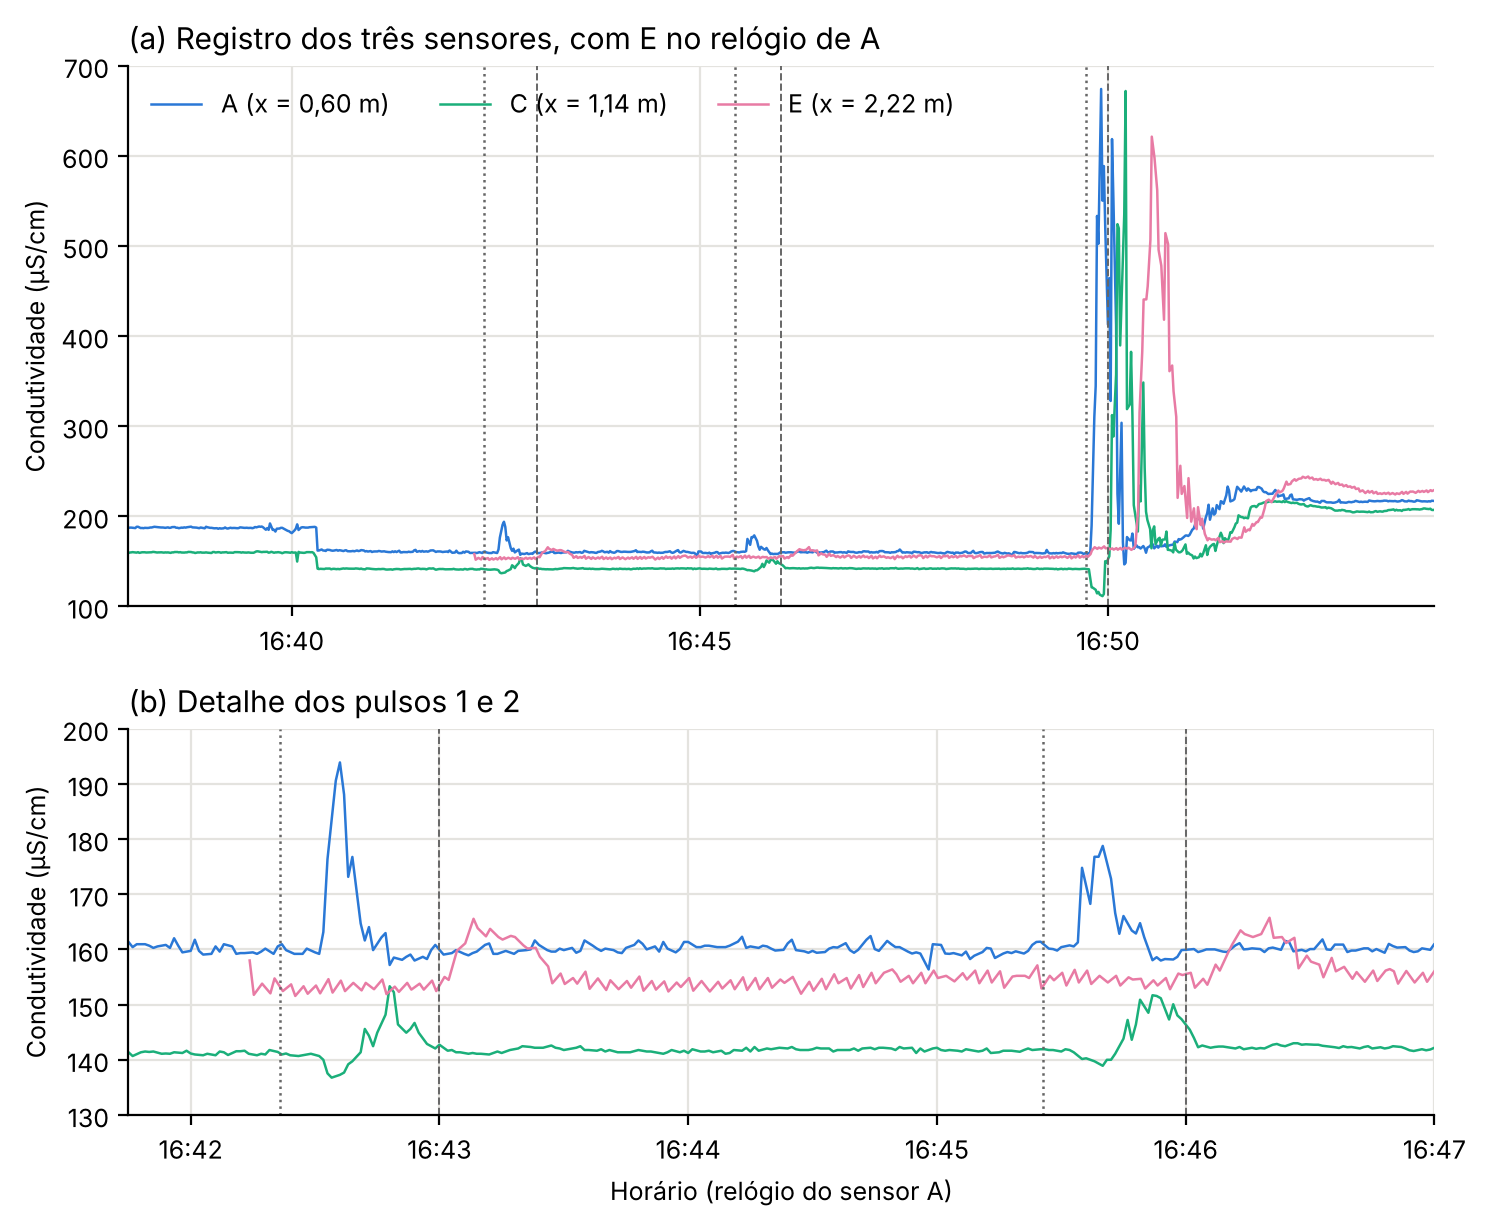

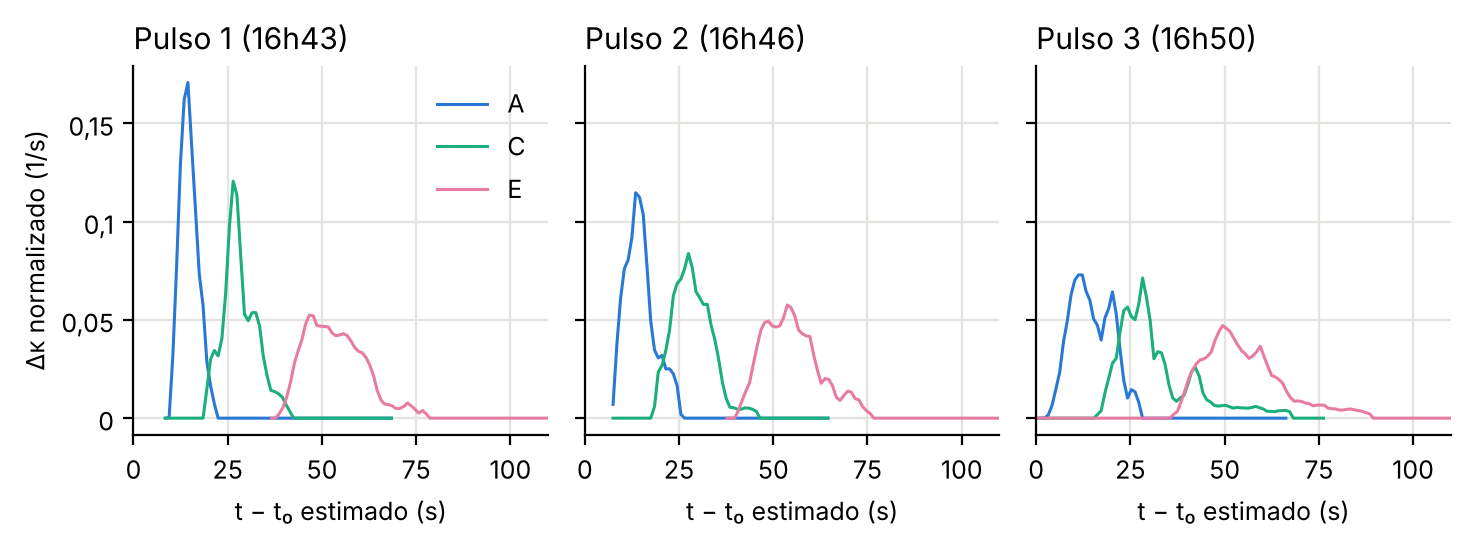

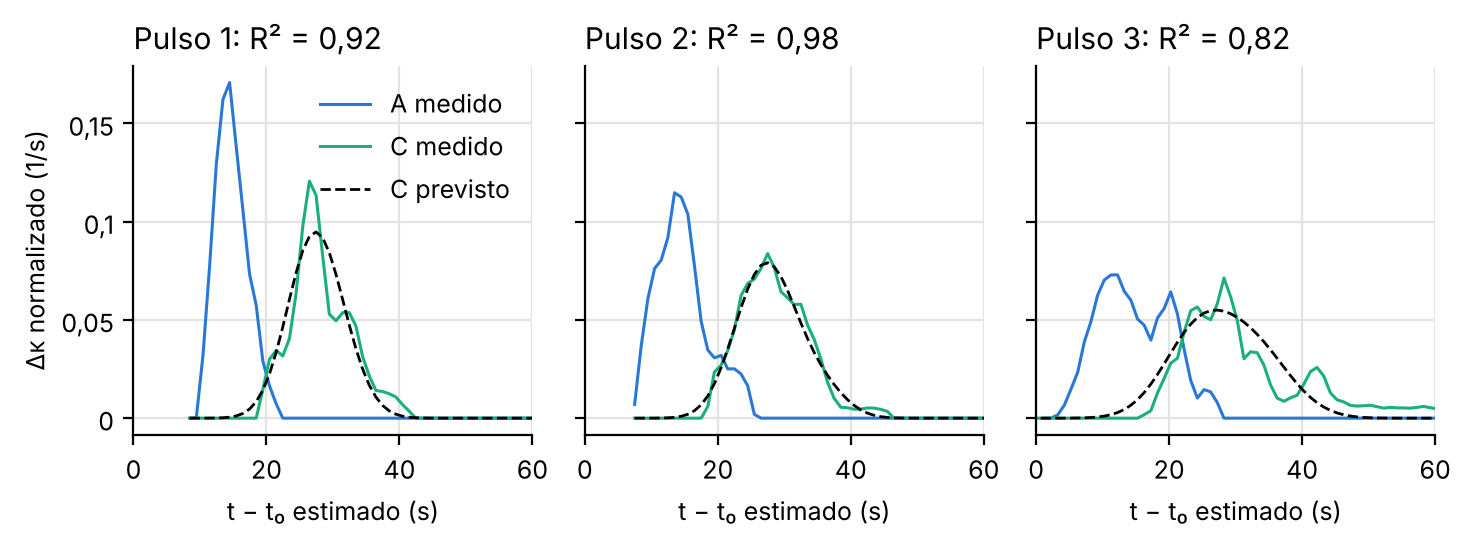

In [12]:
def em_relogio_A(s, idx):
    return idx - pd.Timedelta(seconds=desloc_E) if s == "E" else idx

t0_est = [P[("A", i)]["tm"] - pd.Timedelta(seconds=X["A"] / U_AC) for i in (1, 2, 3)]
print("instante estimado das injeções (relógio de A):", [t.strftime("%H:%M:%S") for t in t0_est])

fig, ax = plt.subplots(2, 1, figsize=(7.5, 6.2), gridspec_kw=dict(height_ratios=[1.4, 1]))
for s in "ACE":
    d = dados[s].CE
    ax[0].plot(em_relogio_A(s, d.index), d.values, color=CORES[s], lw=0.9, label=f"{s} (x = {X[s]:.2f} m)".replace(".", ","))
    g = G[s]
    ax[1].plot(em_relogio_A(s, g.index), g.values, color=CORES[s], lw=0.9)
for k, (hh, te) in enumerate(zip(INJ_ANOTADA, t0_est)):
    for a in ax:
        a.axvline(pd.Timestamp(DAY + hh), color="0.4", ls="--", lw=0.7)
        a.axvline(te, color="0.4", ls=":", lw=0.9)
ax[0].set_xlim(pd.Timestamp(DAY + "16:38"), pd.Timestamp(DAY + "16:54"))
ax[0].set_ylim(100, 700); ax[0].set_ylabel("Condutividade (µS/cm)"); ax[0].legend(ncol=3, loc="upper left")
ax[0].set_title("(a) Registro dos três sensores, com E no relógio de A", loc="left")
ax[1].set_xlim(pd.Timestamp(DAY + "16:41:45"), pd.Timestamp(DAY + "16:47:00")); ax[1].set_ylim(130, 200)
ax[1].set_ylabel("Condutividade (µS/cm)"); ax[1].set_xlabel("Horário (relógio do sensor A)")
ax[1].set_title("(b) Detalhe dos pulsos 1 e 2", loc="left")
for a in ax:
    a.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
fig.tight_layout(); fig.savefig(PASTA_FIG / "F12_exp2610_series.pdf"); fig.savefig(PASTA_FIG / "F12_exp2610_series.png"); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(7.5, 2.8), sharey=True)
for k, i in enumerate((1, 2, 3)):
    for s in "ACE":
        c = P[(s, i)]["curva"]
        t = (em_relogio_A(s, c.index) - t0_est[k]).total_seconds()
        ax[k].plot(t, c.values, color=CORES[s], lw=1.1, label=s)
    ax[k].set_title(f"Pulso {i} ({INJ_ANOTADA[k].replace(':', 'h')})", loc="left")
    ax[k].set_xlim(0, 110); ax[k].set_xlabel("t − t₀ estimado (s)")
ax[0].set_ylabel("Δκ normalizado (1/s)"); ax[0].legend(); ax[0].yaxis.set_major_formatter(VIRG)
fig.tight_layout(); fig.savefig(PASTA_FIG / "F13_exp2610_pulsos.pdf"); fig.savefig(PASTA_FIG / "F13_exp2610_pulsos.png"); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(7.5, 2.8), sharey=True)
for k, i in enumerate((1, 2, 3)):
    a, c, r = P[("A", i)]["curva"], P[("C", i)]["curva"], AC.iloc[k]
    ta = (a.index - t0_est[k]).total_seconds(); tc = (c.index - t0_est[k]).total_seconds()
    ax[k].plot(ta, a.values, color=CORES["A"], lw=1.1, label="A medido")
    ax[k].plot(tc, c.values, color=CORES["C"], lw=1.1, label="C medido")
    ax[k].plot(tc, r["prev"].values, color="k", ls="--", lw=1.0, label="C previsto")
    ax[k].set_xlim(0, 60); ax[k].set_xlabel("t − t₀ estimado (s)")
    ax[k].set_title(f"Pulso {i}: R² = {r['R2']:.2f}".replace(".", ","), loc="left")
ax[0].set_ylabel("Δκ normalizado (1/s)"); ax[0].legend(); ax[0].yaxis.set_major_formatter(VIRG)
fig.tight_layout(); fig.savefig(PASTA_FIG / "F14_exp2610_routing_A_C.pdf"); fig.savefig(PASTA_FIG / "F14_exp2610_routing_A_C.png"); plt.show()